# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [1]:
# Run once, then restart the kernel / runtime and run the remaining cells in order.
%pip install -q numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 huggingface_hub==0.34.0

  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [211 lines of output]
      + meson setup /tmp/pip-install-dnn_r69m/pandas_197fe2b9a59e4c9fac78b0caa43d90ac /tmp/pip-install-dnn_r69m/pandas_197fe2b9a59e4c9fac78b0caa43d90ac/.mesonpy-q29kgy9u/build -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --vsenv --native-file=/tmp/pip-install-dnn_r69m/pandas_197fe2b9a59e4c9fac78b0caa43d90ac/.mesonpy-q29kgy9u/build/meson-python-native-file.ini
      The Meson build system
      Version: 1.2.1
      Source dir: /tmp/pip-install-dnn_r69m/pandas_197fe2b9a59e4c9fac78b0caa43d90ac
      Build dir: /tmp/pip-install-dnn_r69m/pandas_197fe2b9a59e4c9fac78b0caa43d90ac/.mesonpy-q29kgy9u/build
      Build type: native build
      Project name: pandas
      Project version: 2.2.2
      C compiler for the host machine: cc (gcc 13.3.0 "cc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0")
      C linker for the host machine: cc ld.bfd 2

Note: you may need to restart the kernel to use updated packages.


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error,
)
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

import joblib
from huggingface_hub import login, HfApi

RANDOM_STATE = 1

# **Loading the dataset**

In [3]:
# Put SuperKart.csv next to this notebook (or set the SUPERKART_CSV environment variable).
DATA_PATH = os.environ.get("SUPERKART_CSV", "SuperKart.csv")
SuperKart_data = pd.read_csv(DATA_PATH)
df = SuperKart_data.copy()

# **Data Overview**

In [4]:
df.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [5]:
df.shape

(8763, 12)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   str    
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   str    
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   str    
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   str    
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   str    
 9   Store_Location_City_Type   8763 non-null   str    
 10  Store_Type                 8763 non-null   str    
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 821.7 KB


In [7]:
df.isna().sum()

Product_Id                   0
Product_Weight               0
Product_Sugar_Content        0
Product_Allocated_Area       0
Product_Type                 0
Product_MRP                  0
Store_Id                     0
Store_Establishment_Year     0
Store_Size                   0
Store_Location_City_Type     0
Store_Type                   0
Product_Store_Sales_Total    0
dtype: int64

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Product_Weight,8763.0,12.653792,2.217320,4.000,11.150,12.660,14.180,22.000
Product_Allocated_Area,8763.0,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_MRP,8763.0,147.032539,30.694110,31.000,126.160,146.740,167.585,266.000
Store_Establishment_Year,8763.0,2002.032751,8.388381,1987.000,1998.000,2009.000,2009.000,2009.000
Product_Store_Sales_Total,8763.0,3464.003640,1065.630494,33.000,2761.715,3452.340,4145.165,8000.000


In [9]:
#duplicate rows
duplicate_rows = df[df.duplicated()]

print(f"Number of duplicate rows: {len(duplicate_rows)}")

Number of duplicate rows: 0


In [10]:
df.nunique()

Product_Id                   8763
Product_Weight               1113
Product_Sugar_Content           4
Product_Allocated_Area        228
Product_Type                   16
Product_MRP                  6100
Store_Id                        4
Store_Establishment_Year        4
Store_Size                      3
Store_Location_City_Type        3
Store_Type                      4
Product_Store_Sales_Total    8668
dtype: int64

In [11]:
# list of all categorical variables (Product_Id is a unique key, so it is skipped)
cat_col = df.select_dtypes(exclude=np.number).columns.drop("Product_Id")

# printing the share of each unique value in each categorical column
for column in cat_col:
    print(df[column].value_counts(normalize=True))
    print("-" * 50)

Product_Sugar_Content
Low Sugar    0.557457
Regular      0.256875
No Sugar     0.173342
reg          0.012325
Name: proportion, dtype: float64
--------------------------------------------------
Product_Type
Fruits and Vegetables    0.142531
Snack Foods              0.131119
Frozen Foods             0.092548
Dairy                    0.090836
Household                0.084446
Baking Goods             0.081707
Canned                   0.077257
Health and Hygiene       0.071665
Meat                     0.070524
Soft Drinks              0.059226
Breads                   0.022823
Hard Drinks              0.021226
Others                   0.017232
Starchy Foods            0.016090
Breakfast                0.012096
Seafood                  0.008673
Name: proportion, dtype: float64
--------------------------------------------------
Store_Id
OUT004    0.533607
OUT001    0.180988
OUT003    0.153943
OUT002    0.131462
Name: proportion, dtype: float64
-----------------------------------------------

# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

In [12]:
# function to plot a boxplot and a histogram along the same scale.

def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

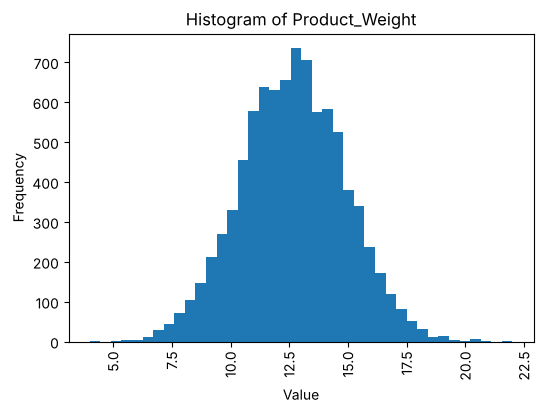

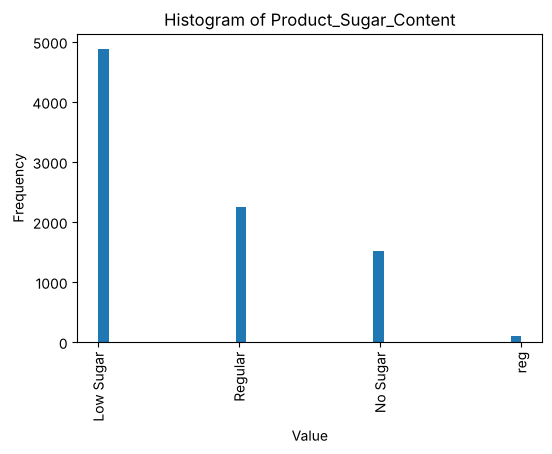

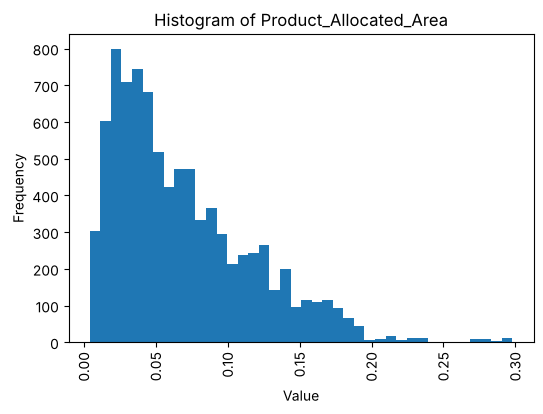

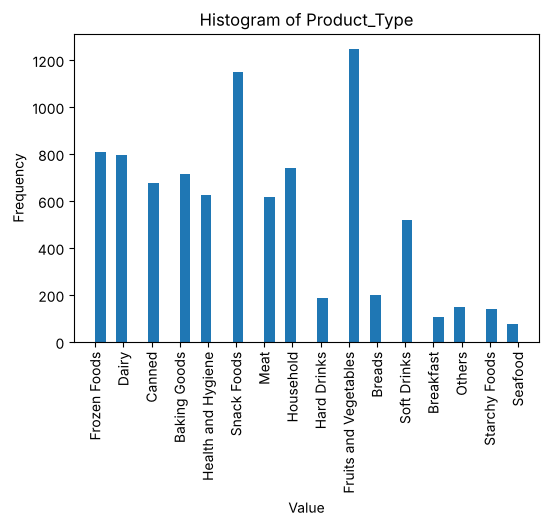

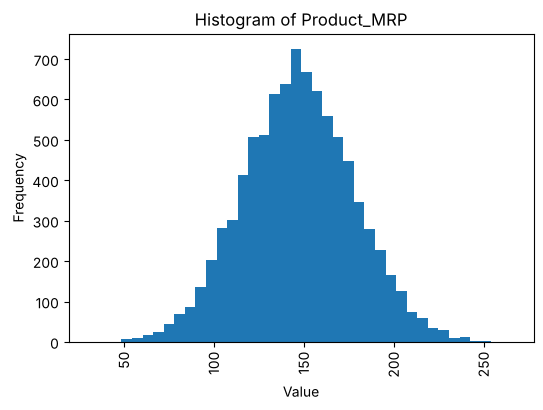

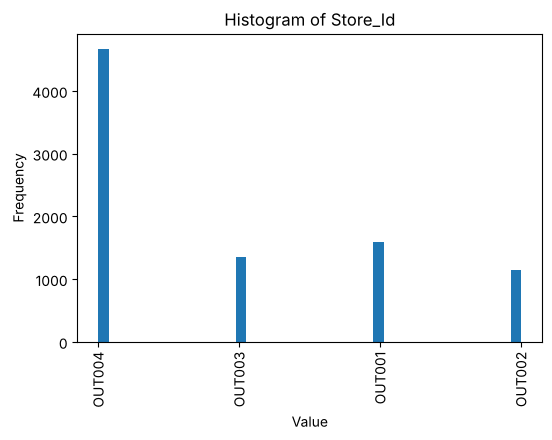

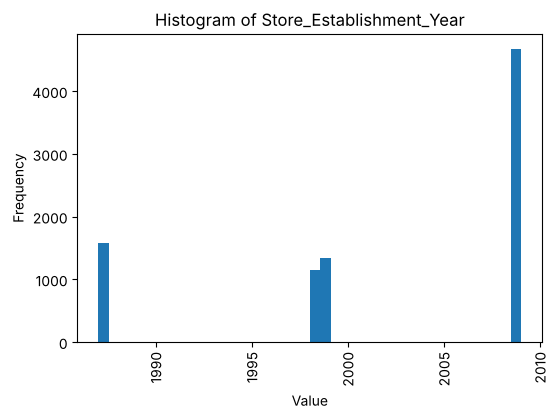

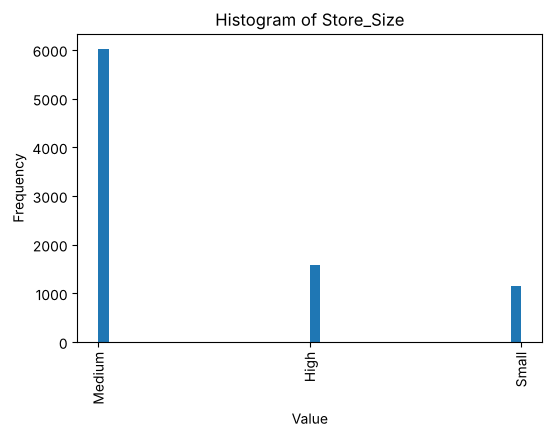

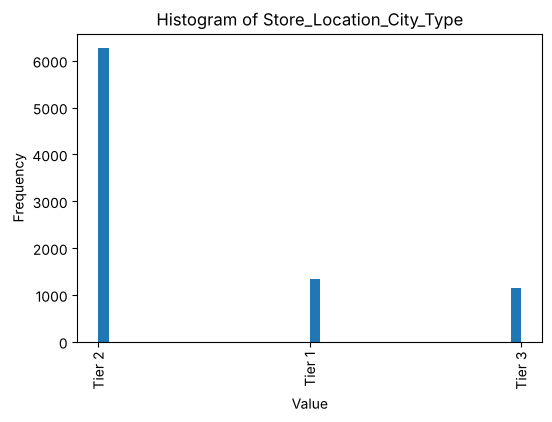

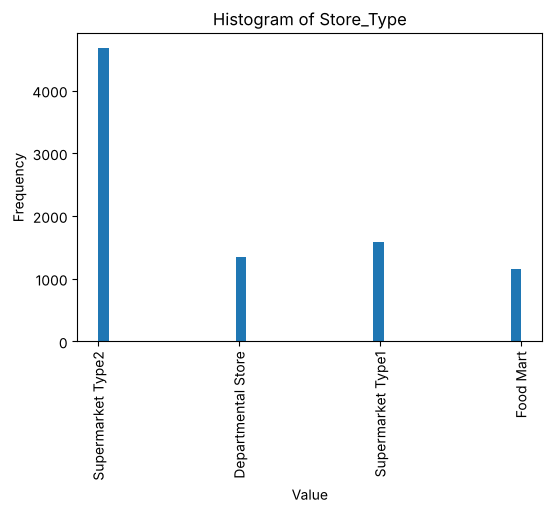

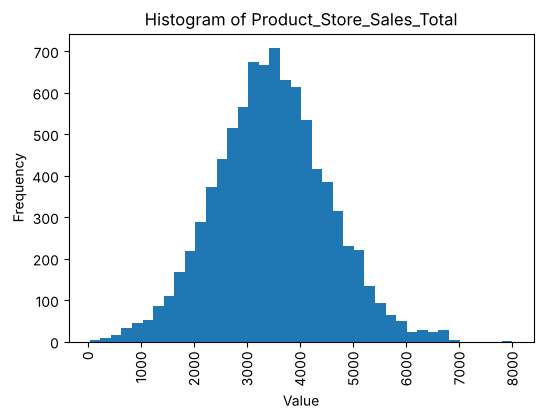

In [13]:
# Histogram of every column except the unique key Product_Id
for column in df.columns.drop("Product_Id"):
    plt.figure(figsize=(6, 4))
    plt.hist(df[column], bins=40)
    plt.xticks(rotation=90)
    plt.title(f"Histogram of {column}")
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.show()
    plt.close()

Main observations (each row is one product in one store):

- Product weight is centred around 12.7 and MRP around 147.
- Low Sugar is the most common sugar category; "reg" is a typo for "Regular" (fixed later).
- Most products take under 10% of a store's display area; a few take up to about 30%.
- Fruits and Vegetables and Snack Foods have the most rows (the most SKUs).
- The dataset covers only **four stores** (OUT001-OUT004). OUT004 contributes more than half of the rows (4,676 of 8,763).
- Mean sales per row is about 3,464 (median close to it), not "just under 4,000".

In [14]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

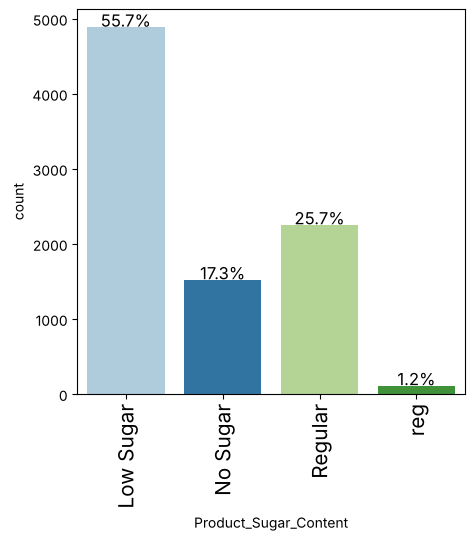

In [15]:
labeled_barplot(df, "Product_Sugar_Content", perc=True)

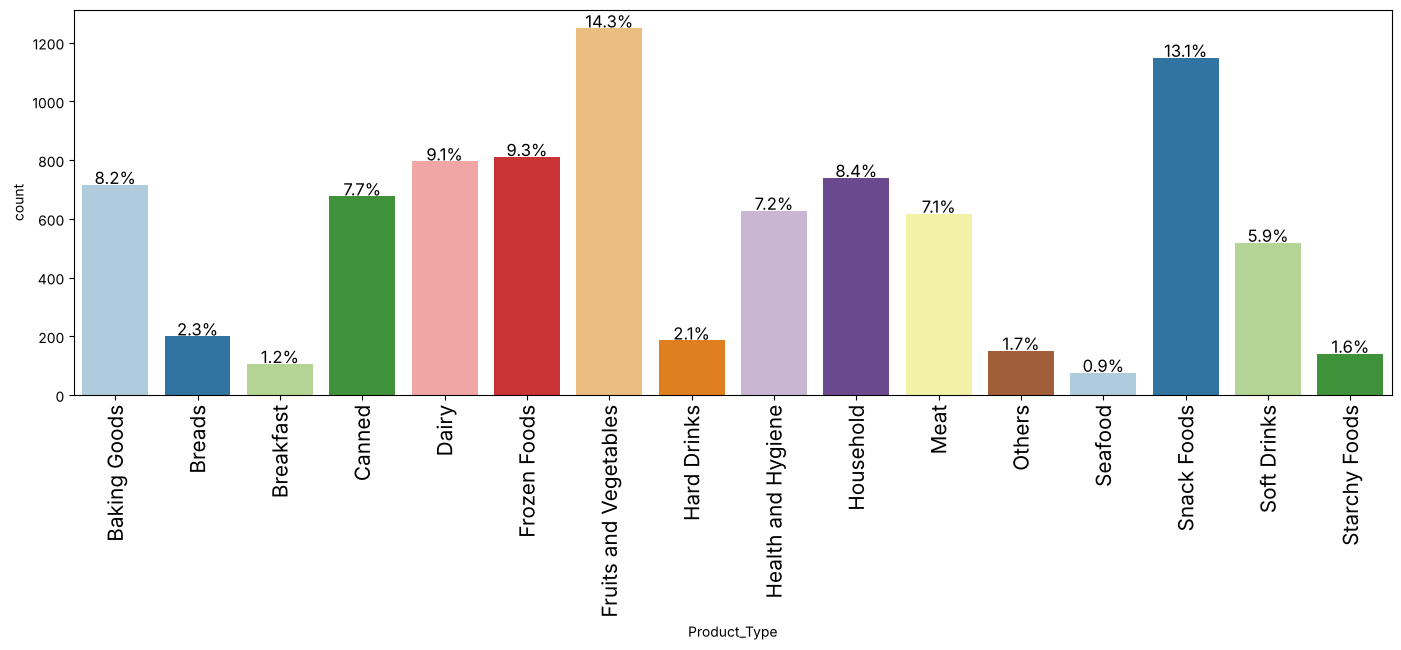

In [16]:
labeled_barplot(df, "Product_Type", perc=True)

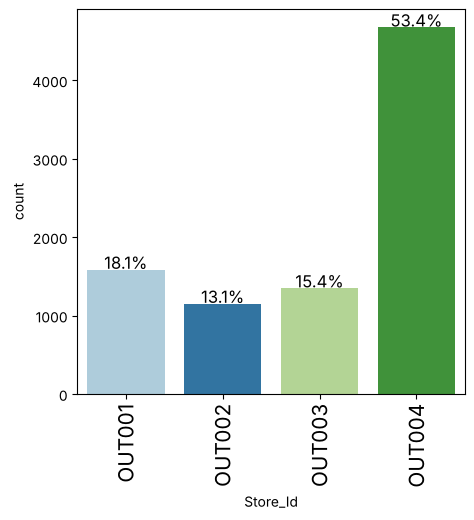

In [17]:
labeled_barplot(df, "Store_Id", perc=True)

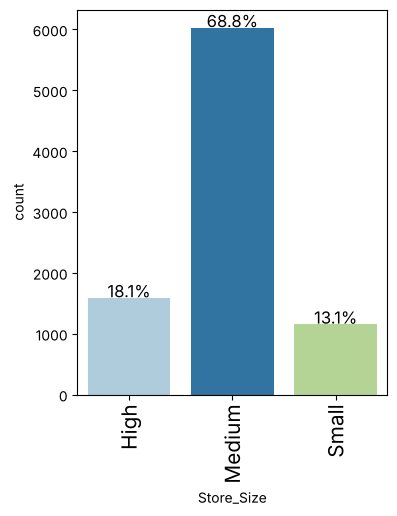

In [18]:
labeled_barplot(df, "Store_Size", perc=True)

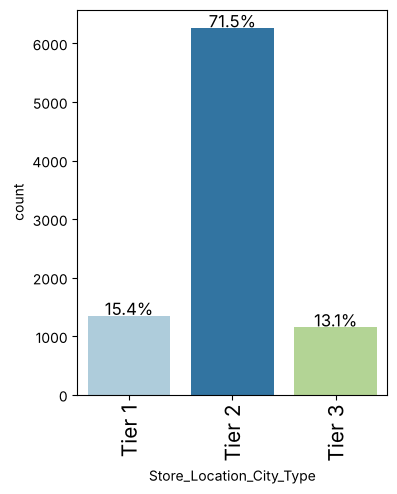

In [19]:
labeled_barplot(df, "Store_Location_City_Type", perc=True)

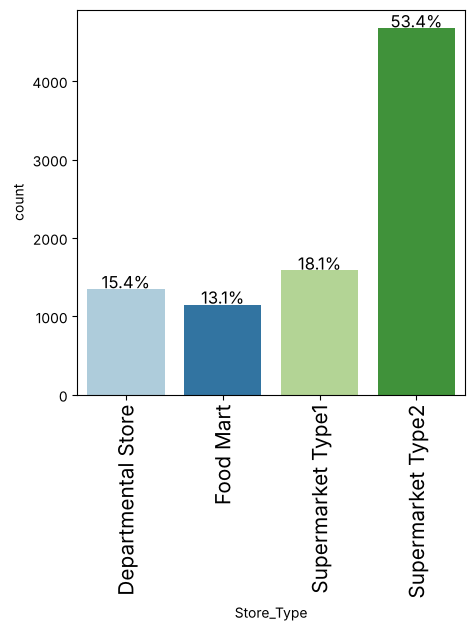

In [20]:
labeled_barplot(df, "Store_Type", perc=True)

The bar plots showed the same results as the histograms.

## Bivariate Analysis

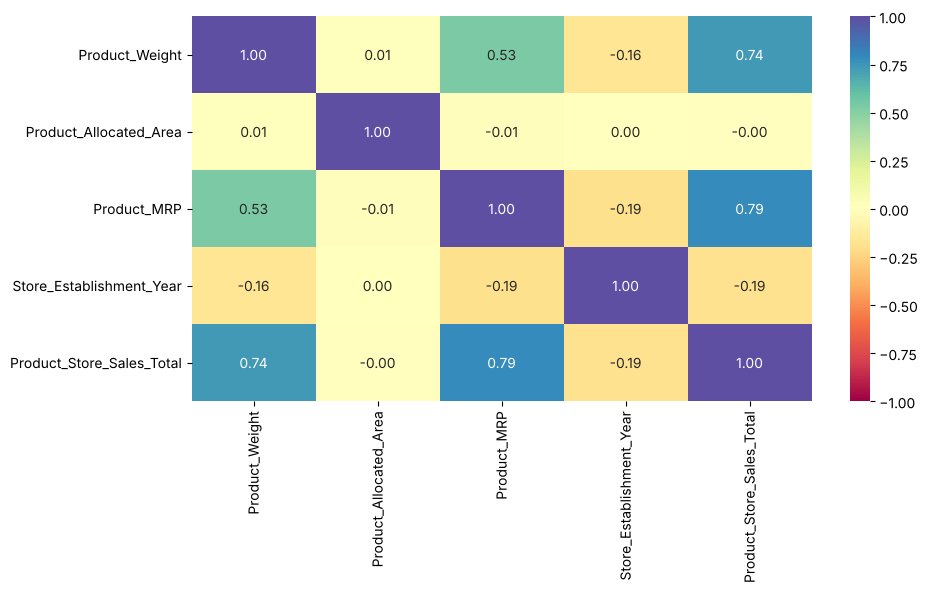

In [21]:
cols_list = df.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(10, 5))
sns.heatmap(
    df[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

`Product_Store_Sales_Total` is strongly correlated with `Product_MRP` (about 0.79) and `Product_Weight` (about 0.74); weight and MRP are moderately correlated with each other (about 0.53). Allocated display area has essentially no linear correlation with sales.

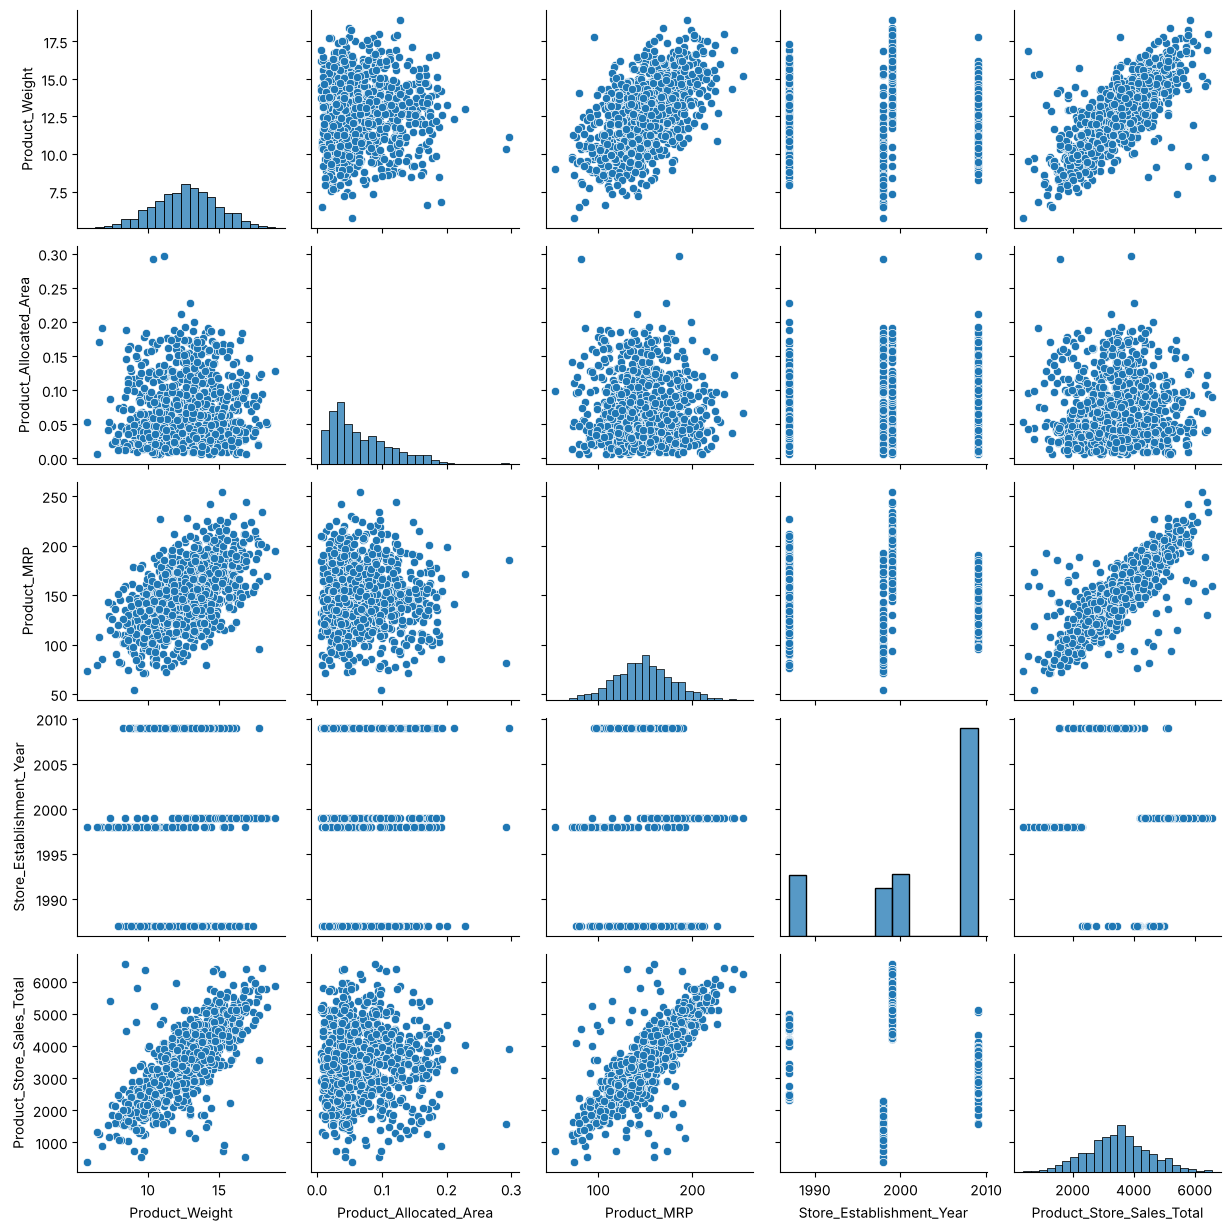

In [22]:
sns.pairplot(data=df.sample(1000))
plt.show()

The pairplot shows the same results as the heatmap.

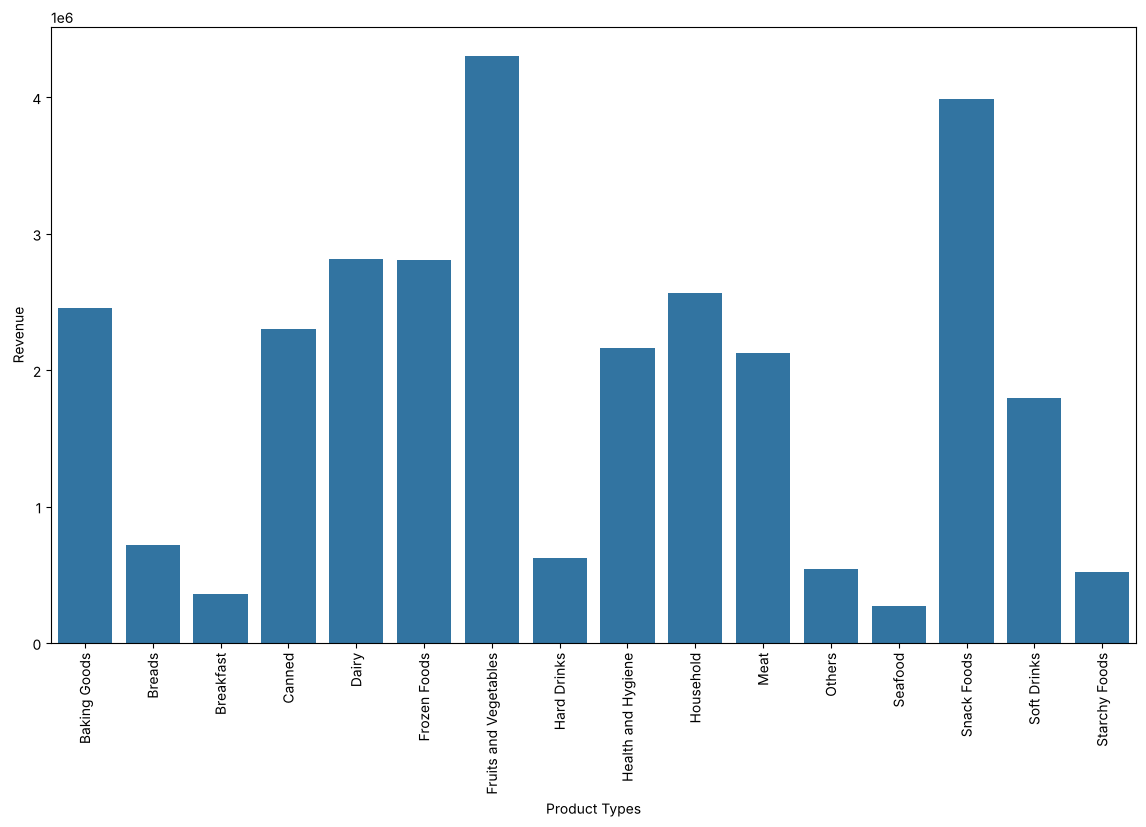

In [23]:
df_revenue1 = df.groupby(["Product_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[14, 8])
plt.xticks(rotation=90)
a = sns.barplot(x=df_revenue1.Product_Type, y=df_revenue1.Product_Store_Sales_Total)
a.set_xlabel("Product Types")
a.set_ylabel("Revenue")
plt.show()

Breakfast, Seafood and Starchy Foods have the smallest **total** sales and Fruits and Vegetables and Snack Foods the largest. Note that these totals mostly reflect how many rows (products) each category has: the average sales per row is almost the same for every category (see the comparison further down).

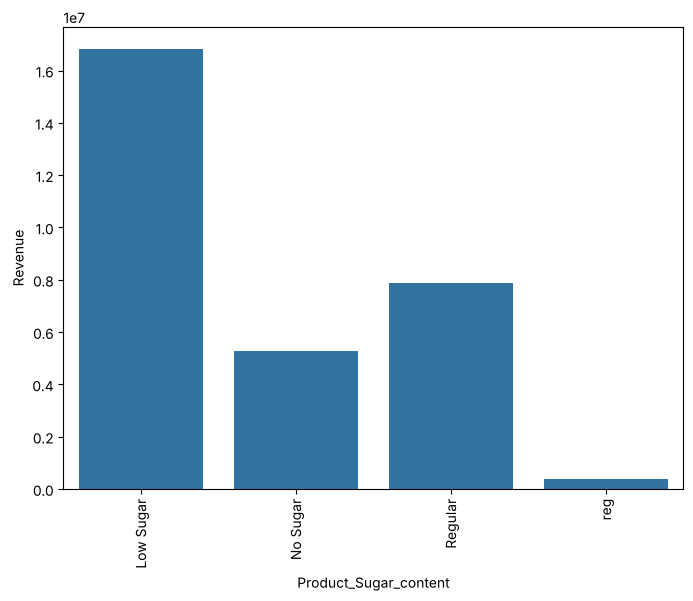

In [24]:
df_revenue2 = df.groupby(["Product_Sugar_Content"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
b = sns.barplot(
    x=df_revenue2.Product_Sugar_Content, y=df_revenue2.Product_Store_Sales_Total
)
b.set_xlabel("Product_Sugar_content")
b.set_ylabel("Revenue")
plt.show()

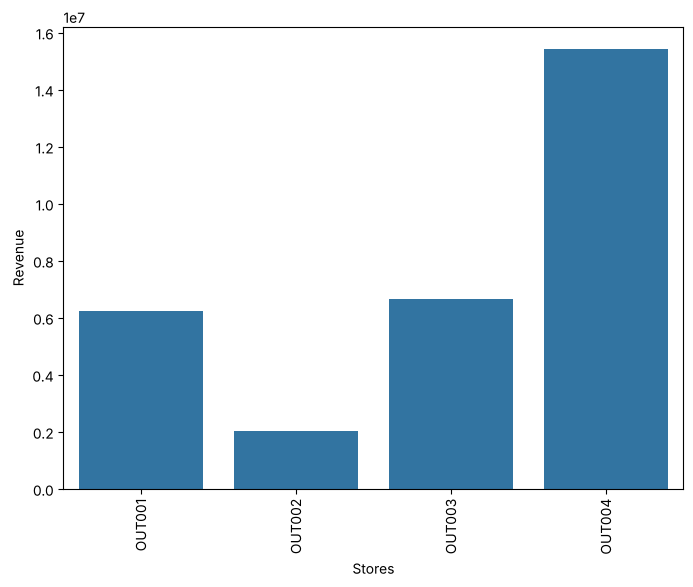

In [25]:
df_store_revenue = df.groupby(["Store_Id"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
r = sns.barplot(
    x=df_store_revenue.Store_Id, y=df_store_revenue.Product_Store_Sales_Total
)
r.set_xlabel("Stores")
r.set_ylabel("Revenue")
plt.show()

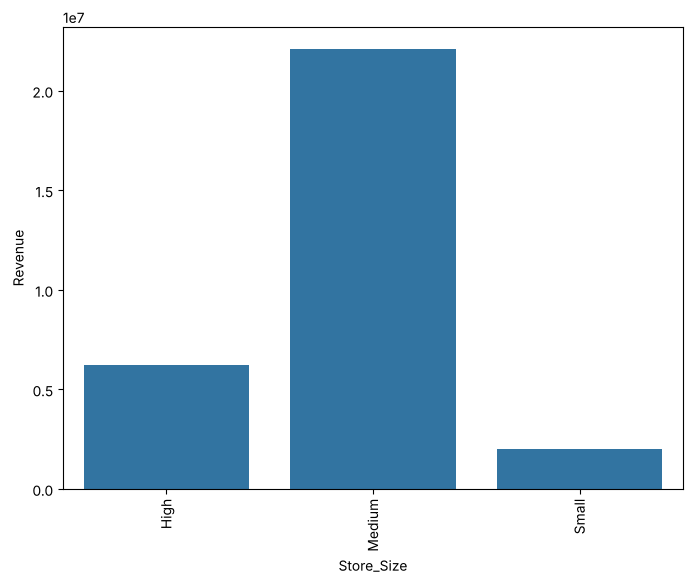

In [26]:
df_revenue3 = df.groupby(["Store_Size"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
c = sns.barplot(x=df_revenue3.Store_Size, y=df_revenue3.Product_Store_Sales_Total)
c.set_xlabel("Store_Size")
c.set_ylabel("Revenue")
plt.show()

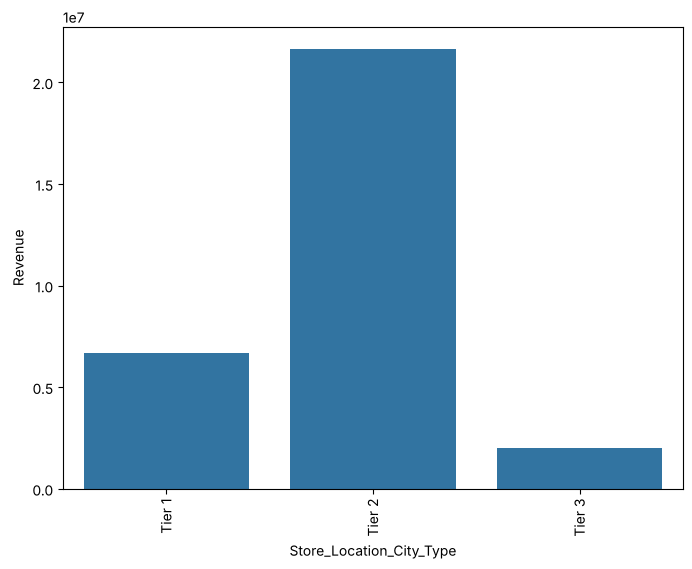

In [27]:
df_revenue4 = df.groupby(["Store_Location_City_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
d = sns.barplot(
    x=df_revenue4.Store_Location_City_Type, y=df_revenue4.Product_Store_Sales_Total
)
d.set_xlabel("Store_Location_City_Type")
d.set_ylabel("Revenue")
plt.show()

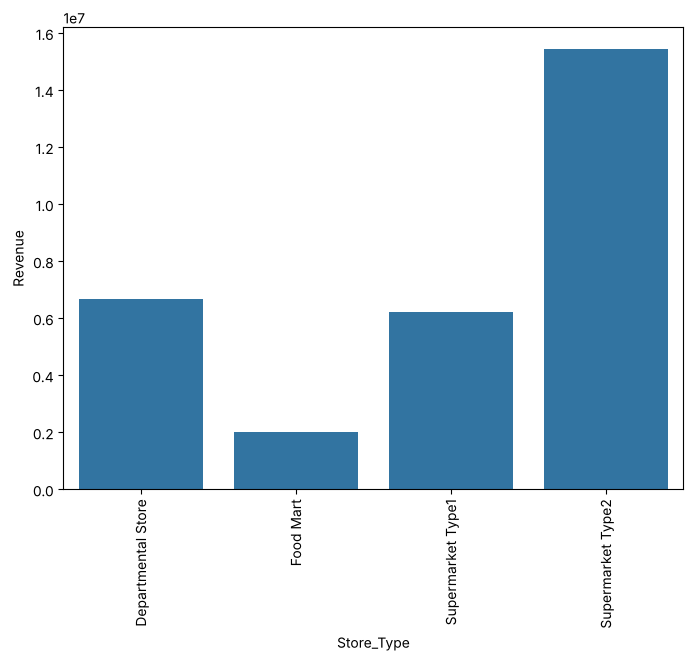

In [28]:
df_revenue5 = df.groupby(["Store_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
e = sns.barplot(x=df_revenue5.Store_Type, y=df_revenue5.Product_Store_Sales_Total)
e.set_xlabel("Store_Type")
e.set_ylabel("Revenue")
plt.show()

In [29]:
# Total revenue depends on how many products a group has; average sales per row is the fairer comparison.
def total_vs_mean(col):
    out = df.groupby(col).agg(
        rows=("Product_Store_Sales_Total", "size"),
        total_sales=("Product_Store_Sales_Total", "sum"),
        mean_sales_per_row=("Product_Store_Sales_Total", "mean"),
        mean_MRP=("Product_MRP", "mean"),
    ).round(1)
    return out.sort_values("mean_sales_per_row", ascending=False)

for col in ["Store_Id", "Store_Type", "Product_Type"]:
    display(total_vs_mean(col))

,rows,total_sales,mean_sales_per_row,mean_MRP
Store_Id,,,,
OUT003,1349,6673457.6,4947.0,181.4
OUT001,1586,6223113.2,3923.8,160.5
OUT004,4676,15427583.4,3299.3,142.4
OUT002,1152,2030909.7,1762.9,107.1


,rows,total_sales,mean_sales_per_row,mean_MRP
Store_Type,,,,
Departmental Store,1349,6673457.6,4947.0,181.4
Supermarket Type1,1586,6223113.2,3923.8,160.5
Supermarket Type2,4676,15427583.4,3299.3,142.4
Food Mart,1152,2030909.7,1762.9,107.1


,rows,total_sales,mean_sales_per_row,mean_MRP
Product_Type,,,,
Starchy Foods,141,518774.4,3679.3,151.3
Others,151,541496.3,3586.1,150.7
Seafood,76,272404.0,3584.3,148.2
Breads,200,714942.2,3574.7,148.9
Dairy,796,2811918.0,3532.6,148.6
Snack Foods,1149,3988997.0,3471.7,147.5
Household,740,2564740.2,3465.9,147.4
Frozen Foods,811,2809980.8,3464.8,146.8
Soft Drinks,519,1797044.7,3462.5,146.8


**Total vs average sales.** OUT004 has the highest total sales (about 15.4M) only because it has by far the most rows. Per row, **OUT003** (Departmental Store, Tier 1) is best at about 4,950, then OUT001 (about 3,920), OUT004 (about 3,300) and **OUT002** (Food Mart, Tier 3) is lowest at about 1,760. Product types, by contrast, all average roughly 3,400-3,700 per row, so the large gaps in category totals come from how many products each category has, not from how well each product sells.

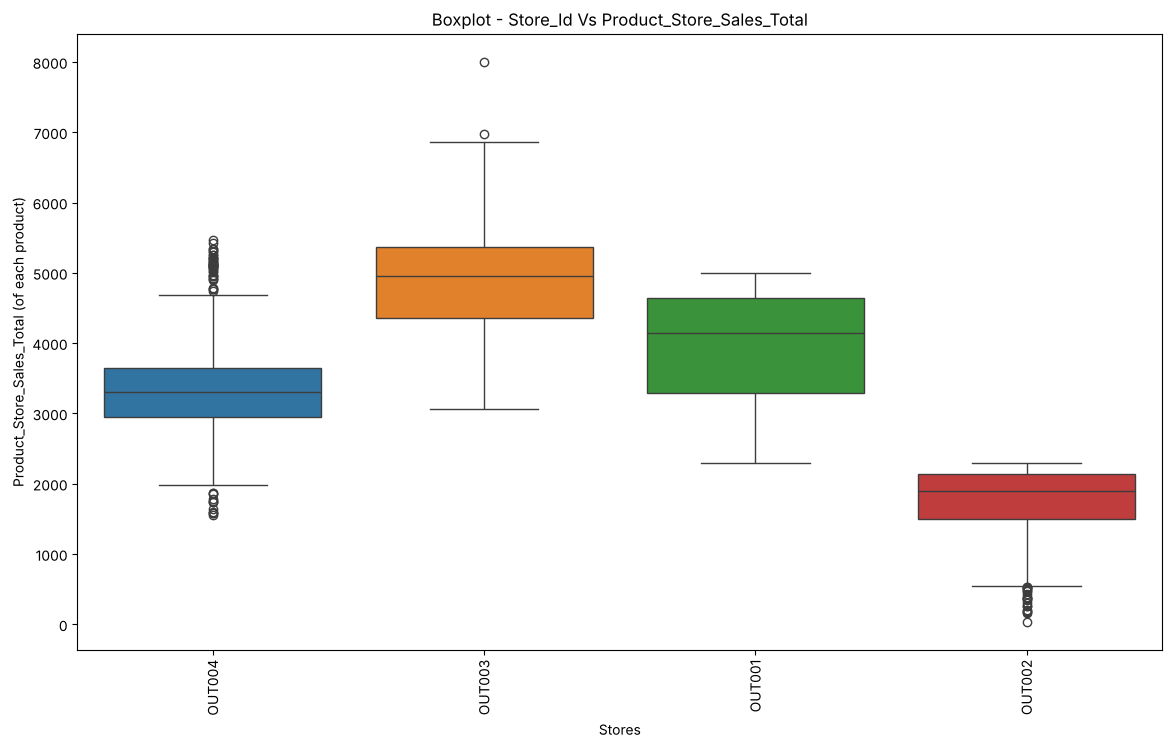

In [30]:
plt.figure(figsize=[14, 8])
sns.boxplot(data=df, x="Store_Id", y="Product_Store_Sales_Total", hue = "Store_Id")
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Id Vs Product_Store_Sales_Total")
plt.xlabel("Stores")
plt.ylabel("Product_Store_Sales_Total (of each product)")
plt.show()

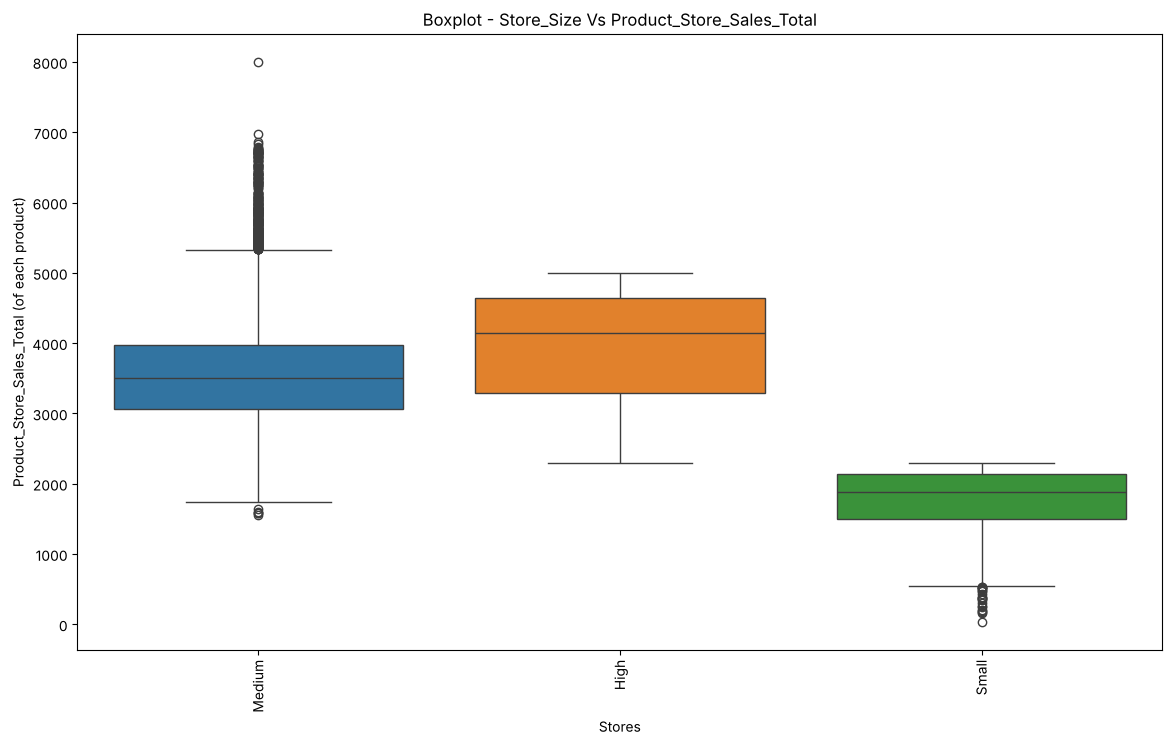

In [31]:
plt.figure(figsize=[14, 8])
sns.boxplot(data = df, x = "Store_Size", y = "Product_Store_Sales_Total", hue = "Store_Size")
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Size Vs Product_Store_Sales_Total")
plt.xlabel("Stores")
plt.ylabel("Product_Store_Sales_Total (of each product)")
plt.show()

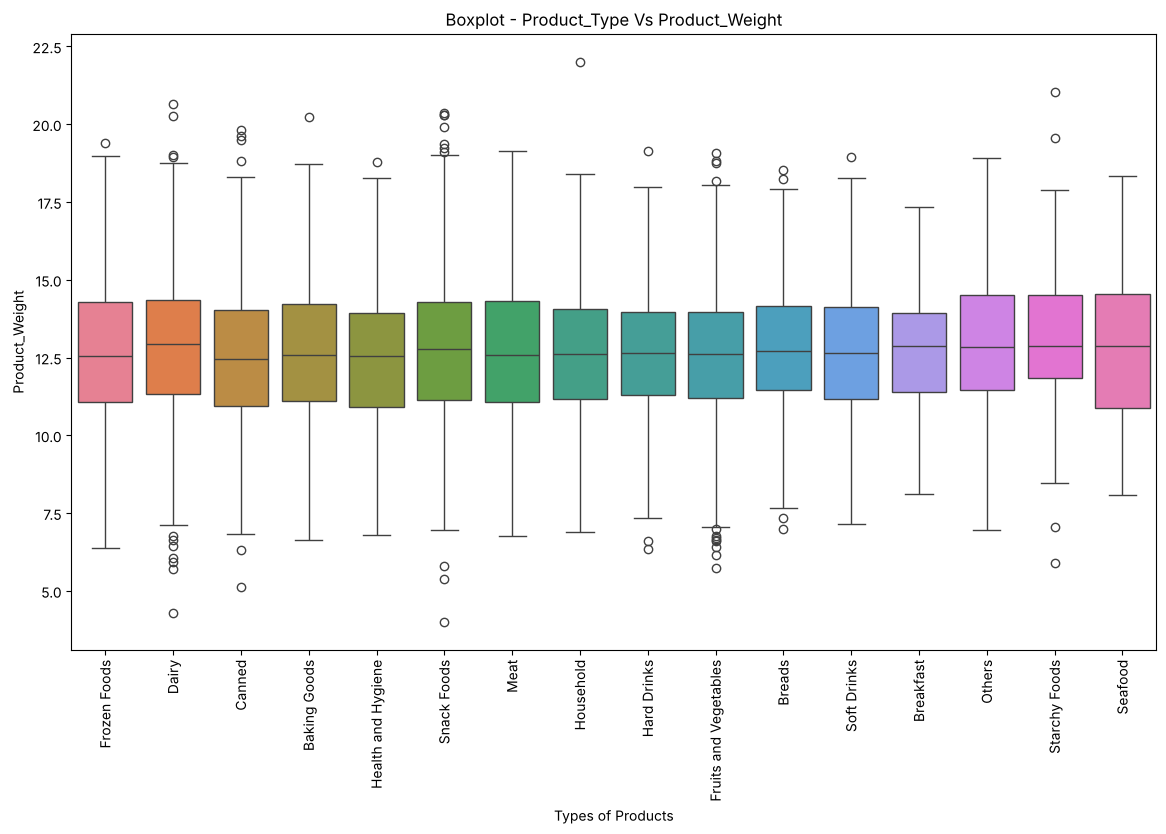

In [32]:
plt.figure(figsize=[14, 8])
sns.boxplot(data = df, x = "Product_Type", y = "Product_Weight", hue = "Product_Type")
plt.xticks(rotation=90)
plt.title("Boxplot - Product_Type Vs Product_Weight")
plt.xlabel("Types of Products")
plt.ylabel("Product_Weight")
plt.show()

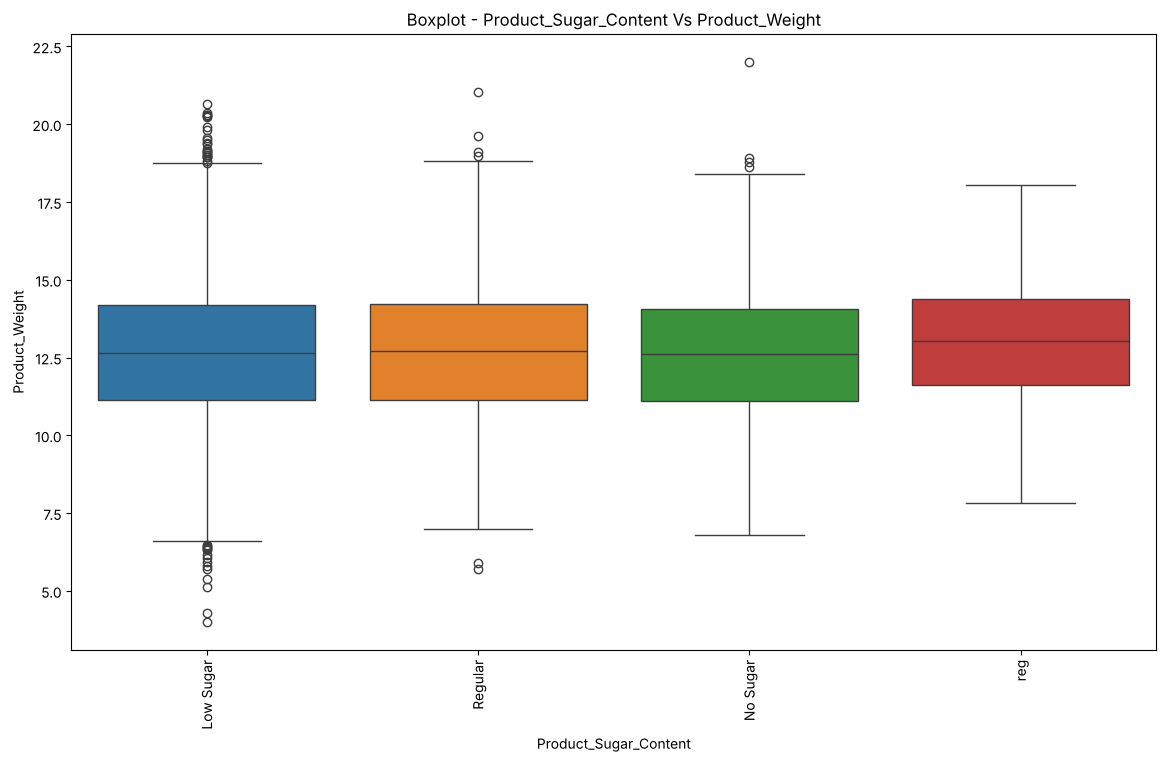

In [33]:
plt.figure(figsize=[14, 8])
sns.boxplot(data = df, x = "Product_Sugar_Content", y = "Product_Weight", hue = "Product_Sugar_Content")
plt.xticks(rotation=90)
plt.title("Boxplot - Product_Sugar_Content Vs Product_Weight")
plt.xlabel("Product_Sugar_Content")
plt.ylabel("Product_Weight")
plt.show()

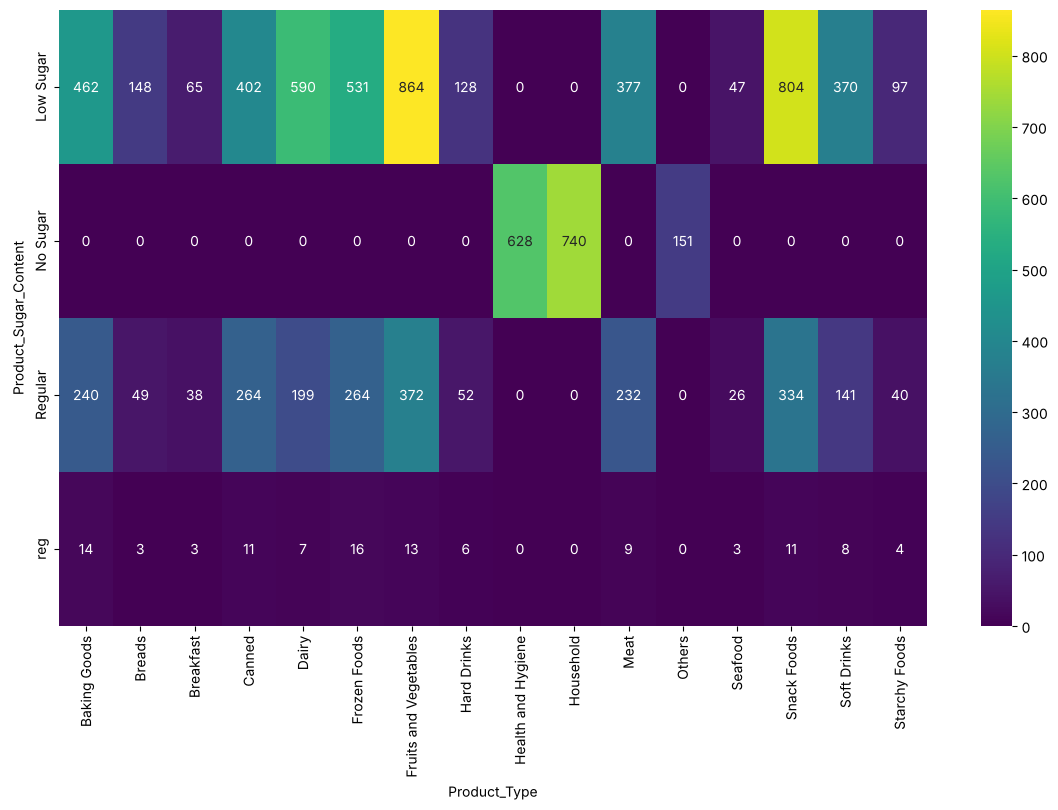

In [34]:
plt.figure(figsize=(14, 8))
sns.heatmap(
    pd.crosstab(df["Product_Sugar_Content"], df["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="viridis",
)
plt.ylabel("Product_Sugar_Content")
plt.xlabel("Product_Type")
plt.show()

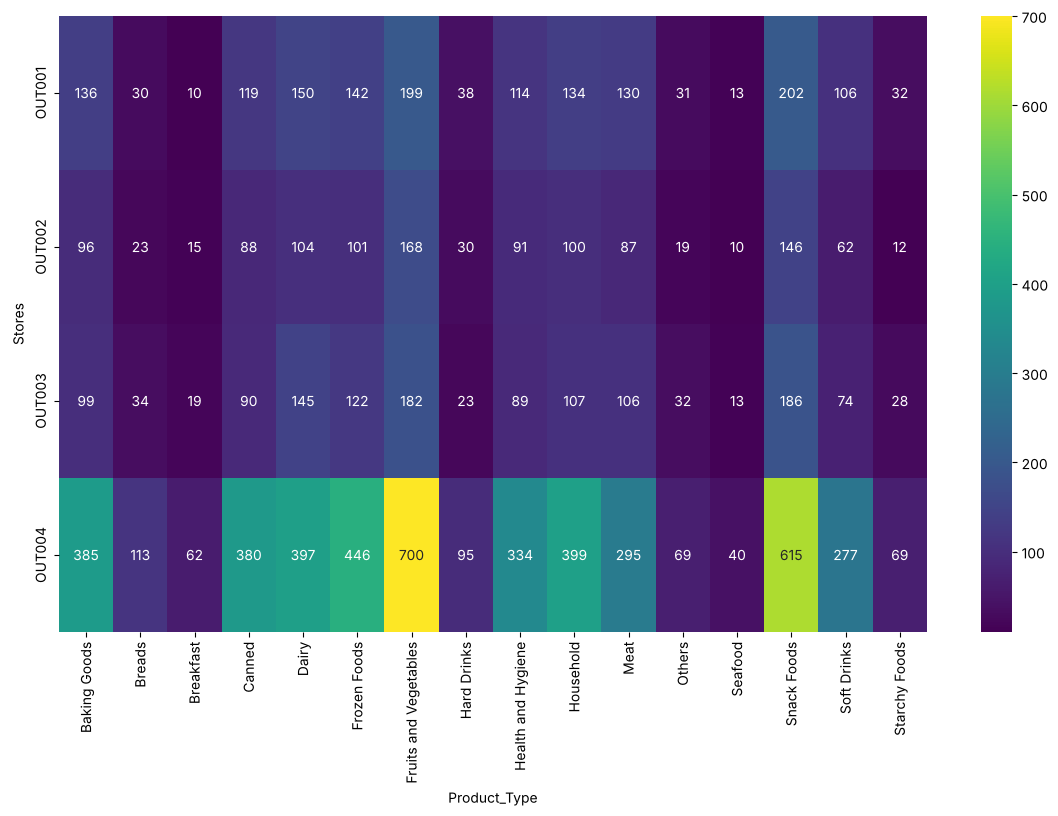

In [35]:
plt.figure(figsize=(14, 8))
sns.heatmap(
    pd.crosstab(df["Store_Id"], df["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="viridis",
)
plt.ylabel("Stores")
plt.xlabel("Product_Type")
plt.show()

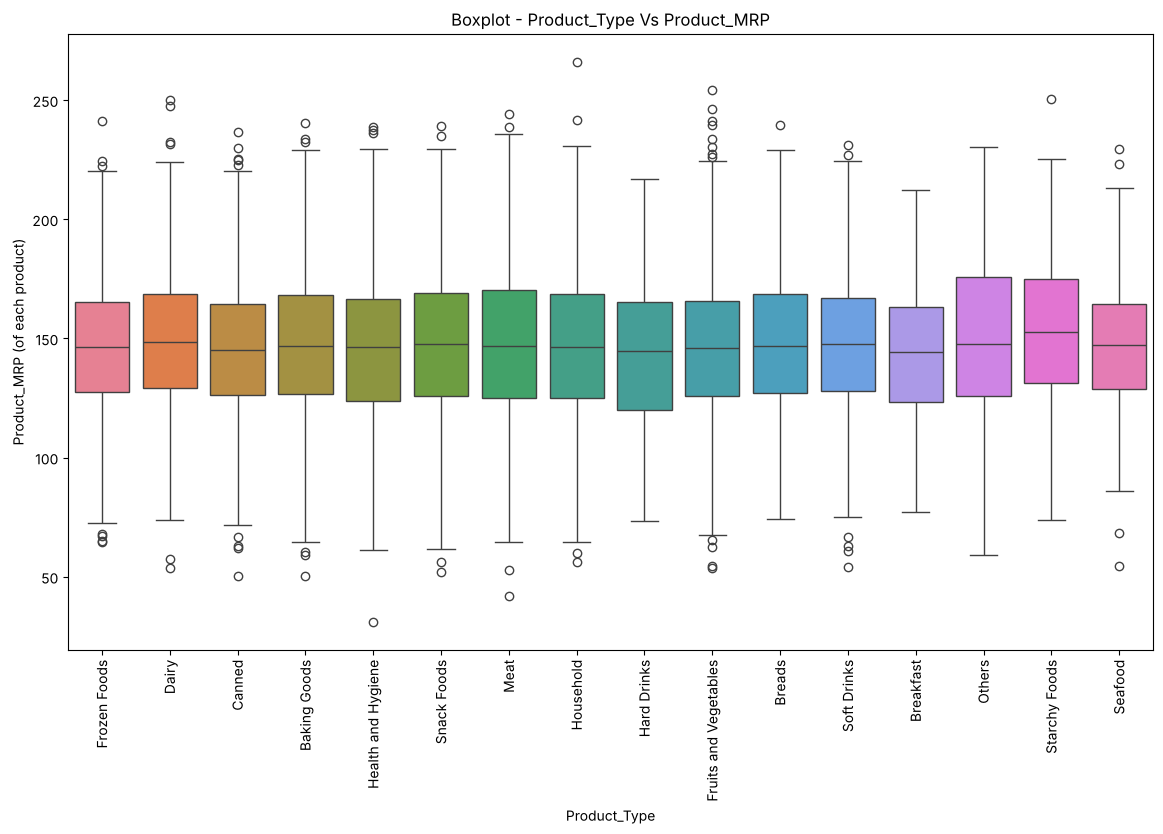

In [36]:
plt.figure(figsize=[14, 8])
sns.boxplot(data = df, x = "Product_Type", y = "Product_MRP", hue = "Product_Type") #Complete the code to plot a boxplot with x as Product_Type , y as Product_MRP and hue as Product_Type
plt.xticks(rotation=90)
plt.title("Boxplot - Product_Type Vs Product_MRP")
plt.xlabel("Product_Type")
plt.ylabel("Product_MRP (of each product)")
plt.show()

All of the MRP are relatively close with Starchy Food and Others being slightly higher.

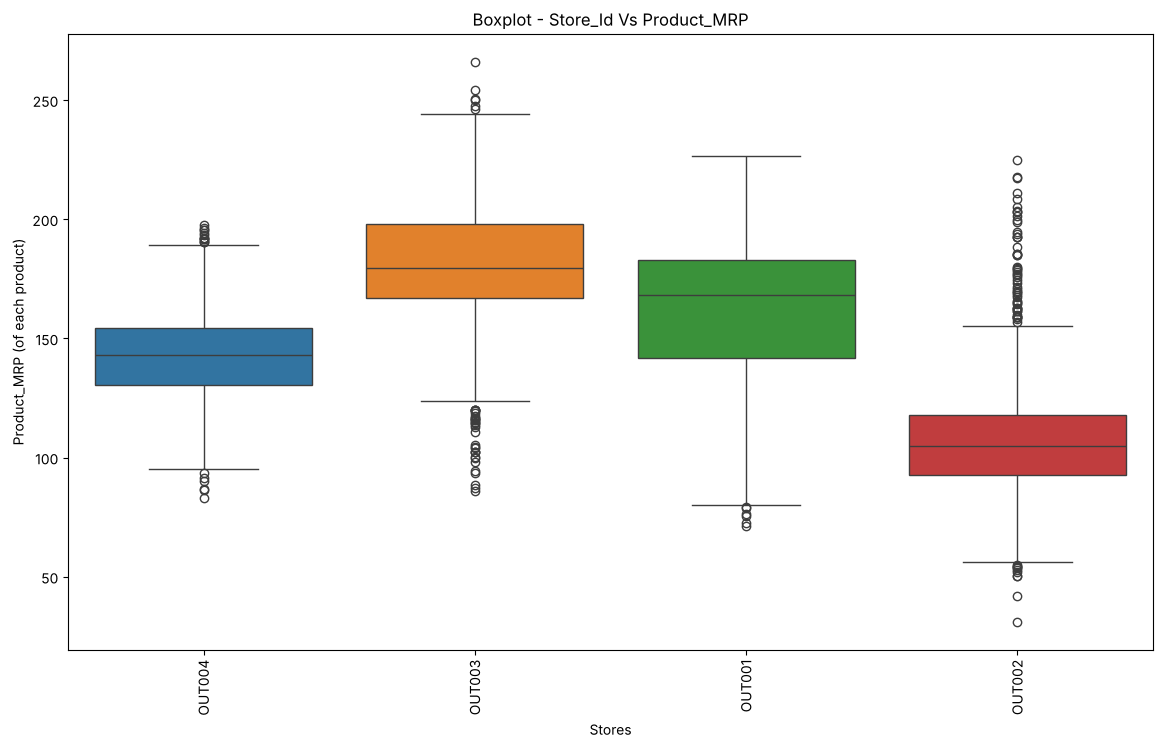

In [37]:
plt.figure(figsize=[14, 8])
sns.boxplot(data = df, x = "Store_Id", y = "Product_MRP", hue = "Store_Id") #Complete the code to plot the boxplot with x as Store_Id , y as Product_MRP and hue as Store_Id
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Id Vs Product_MRP")
plt.xlabel("Stores")
plt.ylabel("Product_MRP (of each product)")
plt.show()

Store OUT003 has the highest prices while store OUT002 has the lowest.

Store OUT003 has the highest prices (average MRP about 181) while OUT002 has the lowest (about 107).

OUT001: rows=1586, total sales=6,223,113.18
OUT002: rows=1152, total sales=2,030,909.72
OUT003: rows=1349, total sales=6,673,457.57
OUT004: rows=4676, total sales=15,427,583.43


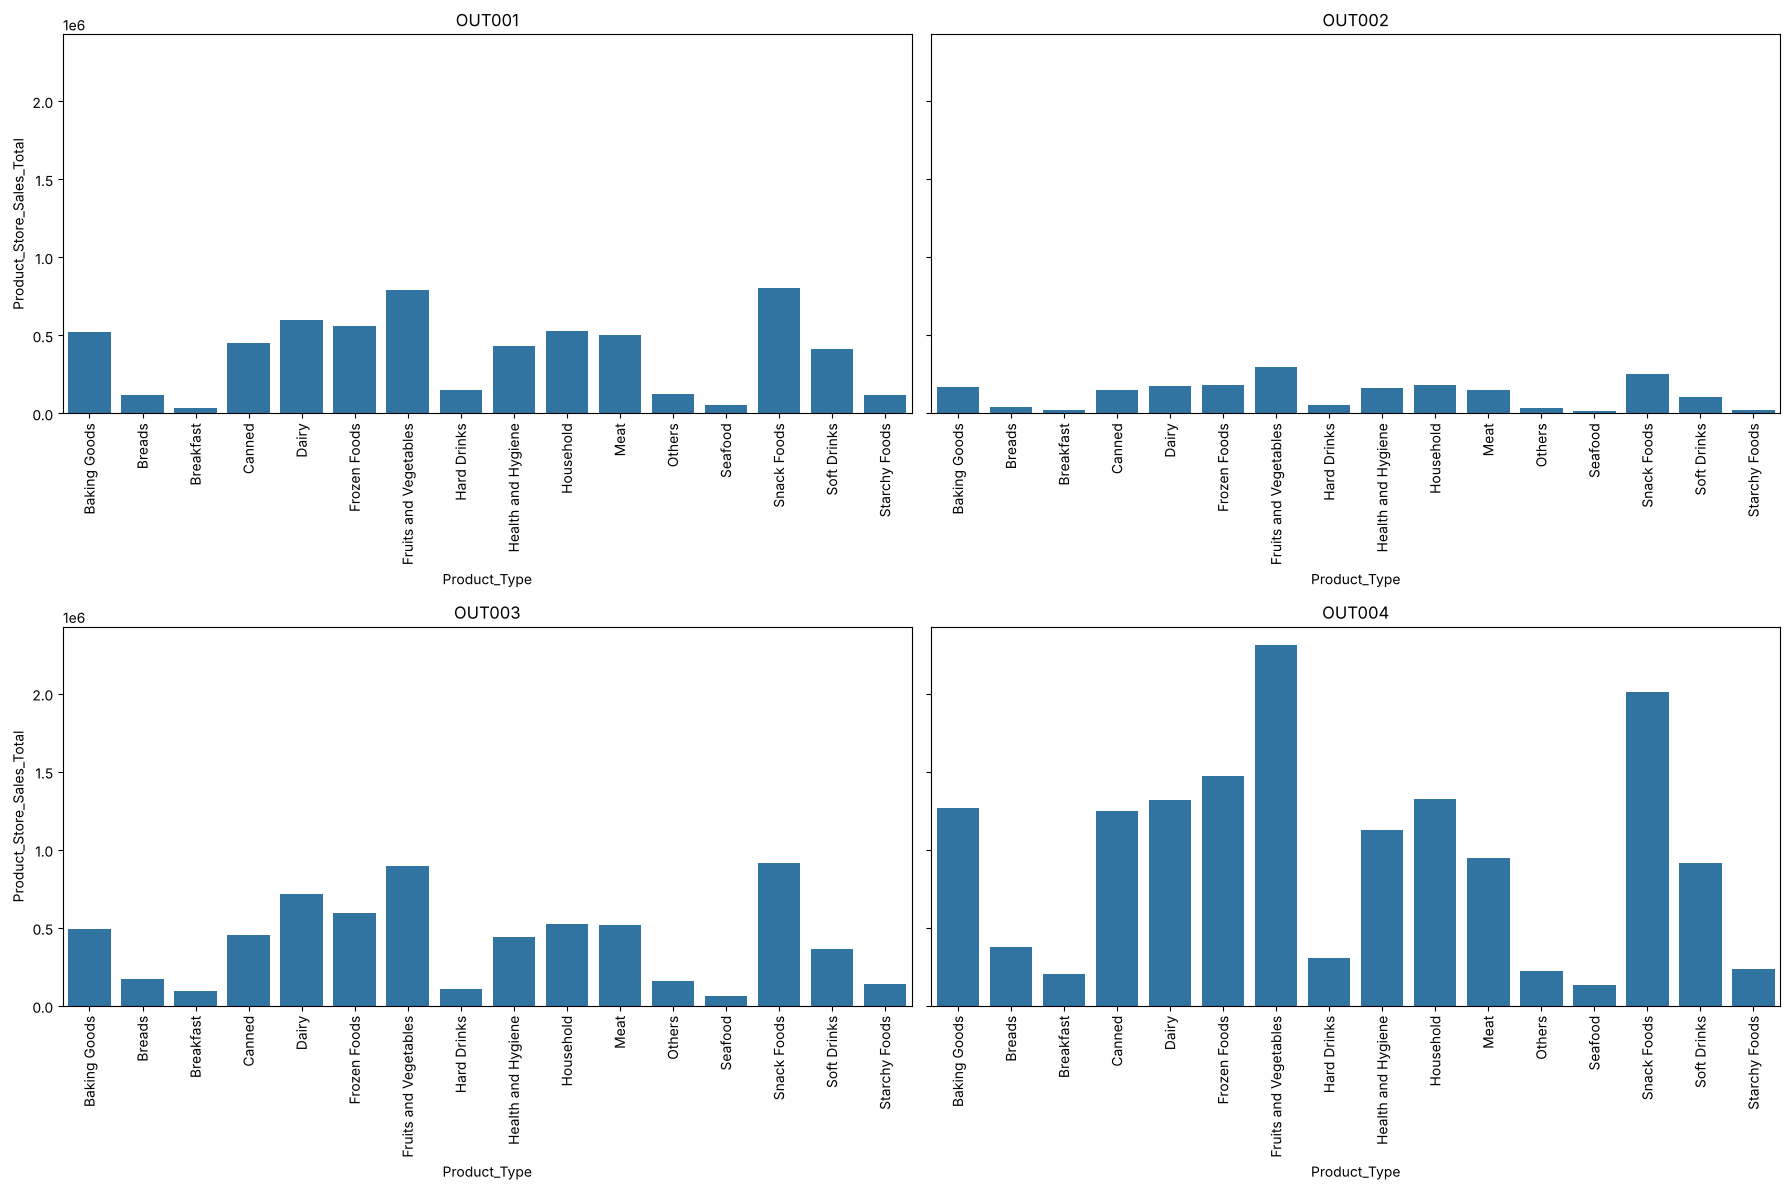

In [38]:
# Per-store summary and sales by product type (each store uses its own data)
stores = sorted(df["Store_Id"].unique())

for s in stores:
    d = df[df["Store_Id"] == s]
    print(f"{s}: rows={len(d)}, total sales={d['Product_Store_Sales_Total'].sum():,.2f}")

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
for ax, s in zip(axes.ravel(), stores):
    by_type = df[df["Store_Id"] == s].groupby("Product_Type")["Product_Store_Sales_Total"].sum()
    sns.barplot(x=by_type.index, y=by_type.values, ax=ax)
    ax.set_title(s)
    ax.set_xlabel("Product_Type")
    ax.set_ylabel("Product_Store_Sales_Total")
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

In every store, Fruits and Vegetables and Snack Foods give the largest total sales and Breakfast, Seafood and Starchy Foods the smallest. As noted above this follows the number of products in each category.

(The original notebook plotted OUT001's values for the OUT002-OUT004 charts, so those three charts were wrong; they are fixed here.)

In [39]:
df1 = df.groupby(["Product_Type", "Store_Id"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
df1

,Product_Type,Store_Id,Product_Store_Sales_Total
0,Baking Goods,OUT001,525131.04
1,Baking Goods,OUT002,169860.50
2,Baking Goods,OUT003,491908.20
3,Baking Goods,OUT004,1266086.26
4,Breads,OUT001,121274.09
5,Breads,OUT002,43419.47
6,Breads,OUT003,175391.93
7,Breads,OUT004,374856.75
8,Breakfast,OUT001,38161.10
9,Breakfast,OUT002,23396.10


In [40]:
df2 = df.groupby(["Product_Sugar_Content", "Store_Id"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
df2

,Product_Sugar_Content,Store_Id,Product_Store_Sales_Total
0,Low Sugar,OUT001,3300834.93
1,Low Sugar,OUT002,1156758.85
2,Low Sugar,OUT003,3706903.24
3,Low Sugar,OUT004,8658908.78
4,No Sugar,OUT001,1090353.78
5,No Sugar,OUT002,382162.19
6,No Sugar,OUT003,1123084.57
7,No Sugar,OUT004,2674343.14
8,Regular,OUT001,1749444.51
9,Regular,OUT002,472112.50


# **Data Preprocessing**

reg and Regular are most likely the exact same things, so those catagories will be combined.

In [41]:
# Replacing "reg" with "Regular" (same category, inconsistent label)
df["Product_Sugar_Content"] = df["Product_Sugar_Content"].replace("reg", "Regular")

In [42]:
df.Product_Sugar_Content.value_counts()

Product_Sugar_Content
Low Sugar    4885
Regular      2359
No Sugar     1519
Name: count, dtype: int64

In [43]:
## extracting the first two characters from the Product_Id column and storing it in another column
df["Product_Id_char"] = df["Product_Id"].str[:2]
df.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC


The product IDs start with a 2 letter code. There are 3 different codes and this section will divide the products into the codes FD, DR and NC.

In [44]:
df["Product_Id_char"].unique()

<StringArray>
['FD', 'NC', 'DR']
Length: 3, dtype: str

In [45]:
df.loc[df.Product_Id_char == "FD", "Product_Type"].unique()

<StringArray>
[         'Frozen Foods',                 'Dairy',                'Canned',
          'Baking Goods',           'Snack Foods',                  'Meat',
 'Fruits and Vegetables',                'Breads',             'Breakfast',
         'Starchy Foods',               'Seafood']
Length: 11, dtype: str

In [46]:
df.loc[df.Product_Id_char == "DR", "Product_Type"].unique()

<StringArray>
['Hard Drinks', 'Soft Drinks']
Length: 2, dtype: str

In [47]:
df.loc[df.Product_Id_char == "NC", "Product_Type"].unique()

<StringArray>
['Health and Hygiene', 'Household', 'Others']
Length: 3, dtype: str

Changing the date of the store's opening to the age of the store. This will make the data easier to understand and use.

In [48]:
# Store age, measured from a fixed reference year so results are reproducible
REFERENCE_YEAR = 2025
df["Store_Age_Years"] = REFERENCE_YEAR - df["Store_Establishment_Year"]

Dividing the store's items into perishable and non perishable items. This will leave 2 catgories instead of 16. That will make the data input much easier when the stores run the models.

In [49]:
perishables = [
    "Dairy",
    "Meat",
    "Fruits and Vegetables",
    "Breakfast",
    "Breads",
    "Seafood",
]

In [50]:
def change(x):
    if x in perishables:
        return "Perishables"
    else:
        return "Non Perishables"

In [51]:
df['Product_Type_Category'] = df['Product_Type'].apply(change)

In [52]:
df.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years,Product_Type_Category
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,16,Non Perishables
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,26,Perishables
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,38,Non Perishables
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,38,Non Perishables
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,27,Non Perishables


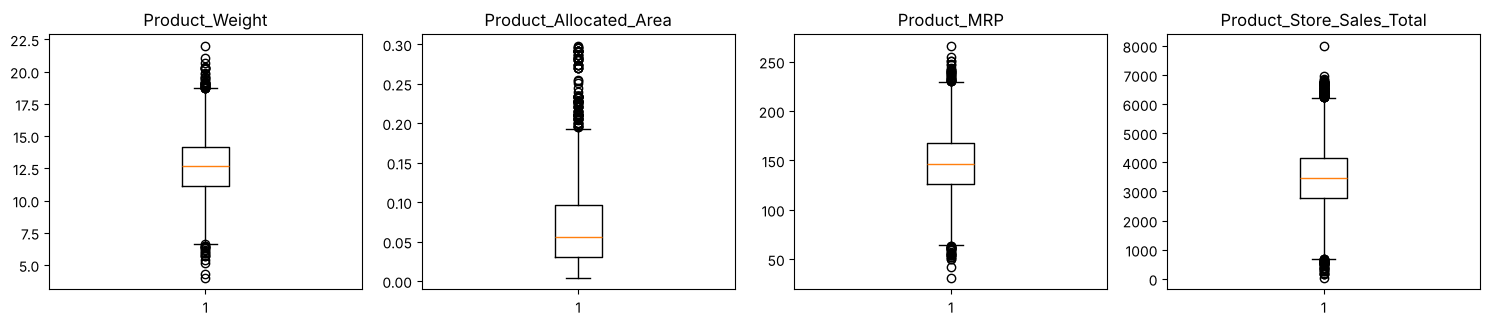

In [53]:
# outlier detection using boxplot
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
numeric_columns.remove("Store_Establishment_Year")
numeric_columns.remove("Store_Age_Years")


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

No outliers are removed or capped. The ensemble tree models used below are robust to them, and the extreme values here look like genuine large or small sales rather than errors.

# **Model Building**

We aim to forecast the Product_Store_Sales_Total.

Before building the model, we'll drop unnecessary columns and encode the categorical features.

We'll then split the data into training and testing sets to evaluate the model's performance on unseen data.

In [54]:
df = df.drop(["Product_Id", "Product_Type","Store_Id","Store_Establishment_Year"], axis=1) #Complete the code to drop the columns "Product_Id","Product_Type","Store_Id","Store_Establishment_Year"

In [55]:
df.shape

(8763, 11)

In [56]:
df.head()

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years,Product_Type_Category
0,12.66,Low Sugar,0.027,117.08,Medium,Tier 2,Supermarket Type2,2842.40,FD,16,Non Perishables
1,16.54,Low Sugar,0.144,171.43,Medium,Tier 1,Departmental Store,4830.02,FD,26,Perishables
2,14.28,Regular,0.031,162.08,High,Tier 2,Supermarket Type1,4130.16,FD,38,Non Perishables
3,12.10,Low Sugar,0.112,186.31,High,Tier 2,Supermarket Type1,4132.18,FD,38,Non Perishables
4,9.57,No Sugar,0.010,123.67,Small,Tier 3,Food Mart,2279.36,NC,27,Non Perishables


In [57]:
X = df.drop("Product_Store_Sales_Total", axis=1)
y = df["Product_Store_Sales_Total"]

In [58]:
# Splitting the data into train and test sets in 70:30 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, shuffle=True
)

In [59]:
X_train.shape, X_test.shape

((6134, 10), (2629, 10))

In [60]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
print("categorical:", categorical_features)
print("numeric:", numeric_features)

categorical: ['Product_Sugar_Content', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Id_char', 'Product_Type_Category']
numeric: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Age_Years']


**Preprocessing fix.** The original column transformer listed only the categorical columns and used the default `remainder="drop"`, so the numeric features (`Product_MRP`, `Product_Weight`, `Product_Allocated_Area`, `Store_Age_Years`) were silently thrown away before every model. Those are the strongest predictors of sales, so this capped the original models at R-squared of about 0.67. The transformer below one-hot encodes the categorical columns and passes the numeric ones through unchanged (tree models do not need scaling).

In [61]:
preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), categorical_features),
    remainder="passthrough",  # keep the numeric features
)

## Define functions for Model Evaluation

In [62]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

Two models are built and tuned: Gradient Boosting and XGBoost (the original author tried several and settled on these two). A model that always predicts the training mean would score an R-squared of about 0, which is the baseline to beat.

In [63]:
gb_estimator = make_pipeline(preprocessor, GradientBoostingRegressor(random_state=RANDOM_STATE))
gb_estimator.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('gradientboostingregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Product_Weight','Product_Sugar_Content','Product_Allocated_Area',..., 'Product_Id_char','Store_Age_Years','Product_Type_Category']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in th

In [64]:
#gradientboost regressor train

gb_estimator_model_train_perf = model_performance_regression(gb_estimator, X_train, y_train)
gb_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,288.211763,137.768444,0.926587,0.926467,0.049865


In [65]:
# gradientboost regressor test

gb_estimator_model_test_perf = model_performance_regression(gb_estimator, X_test, y_test)
gb_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,319.740682,151.849819,0.910662,0.910321,0.064964


In [66]:
xgb_estimator = make_pipeline(preprocessor, XGBRegressor(random_state=RANDOM_STATE))
xgb_estimator.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('xgbregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Product_Weight','Product_Sugar_Content','Product_Allocated_Area',..., 'Product_Id_char','Store_Age_Years','Product_Type_Category']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passed

In [67]:
# xgboost regressor train

xgb_estimator_model_train_perf = model_performance_regression(xgb_estimator, X_train, y_train)
xgb_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,124.262304,57.934247,0.986353,0.986331,0.019526


In [68]:
# xgboost regressor test

xgb_estimator_model_test_perf = model_performance_regression(xgb_estimator, X_test, y_test)
xgb_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,304.864727,132.215849,0.918782,0.918471,0.055272


# **Model Performance Improvement - Hyperparameter Tuning**

Tuning uses `RandomizedSearchCV` with 3-fold cross-validation on the training set and `scoring="r2"`. The original gradient boosting search passed the `r2_score` function as `scoring` instead of the string `"r2"`; that is not a valid scorer, every fit failed quietly (warnings were suppressed), and the "tuned" model was just the first parameter combination. The original XGBoost grid (1,500 combinations x 3 folds) is replaced by a 30-draw random search over the same ranges.

In [69]:
gb_params = {
    "gradientboostingregressor__n_estimators": [100, 200, 300],
    "gradientboostingregressor__subsample": [0.7, 0.8, 0.9, 1.0],
    "gradientboostingregressor__max_features": [0.7, 0.8, 0.9, 1.0],
    "gradientboostingregressor__max_depth": [3, 4, 5, 6],
}
gb_search = RandomizedSearchCV(
    make_pipeline(preprocessor, GradientBoostingRegressor(random_state=RANDOM_STATE)),
    gb_params, n_iter=30, scoring="r2", cv=3, n_jobs=-1, random_state=RANDOM_STATE,
)
gb_search.fit(X_train, y_train)
gb_tuned = gb_search.best_estimator_   # already refit on the full training set
print("Best params:", gb_search.best_params_)
print("Best CV R2 :", round(gb_search.best_score_, 4))

Best params: {'gradientboostingregressor__subsample': 0.8, 'gradientboostingregressor__n_estimators': 100, 'gradientboostingregressor__max_features': 0.7, 'gradientboostingregressor__max_depth': 5}
Best CV R2 : 0.9259


In [70]:
#gradientboost regressor train results

gb_tuned_model_train_perf = model_performance_regression(gb_tuned, X_train, y_train)
gb_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,213.298317,90.362133,0.959791,0.959725,0.031785


In [71]:
#gradientboost regressor test results

gb_tuned_model_test_perf = model_performance_regression(gb_tuned, X_test, y_test)
gb_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,295.792961,122.707546,0.923543,0.923251,0.053012


In [72]:
xgb_params = {
    "xgbregressor__n_estimators": [50, 100, 150, 200],
    "xgbregressor__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "xgbregressor__gamma": [0, 0.1, 0.2, 0.3],
    "xgbregressor__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "xgbregressor__colsample_bylevel": [0.6, 0.7, 0.8, 0.9, 1.0],
}
xgb_search = RandomizedSearchCV(
    make_pipeline(preprocessor, XGBRegressor(random_state=RANDOM_STATE)),
    xgb_params, n_iter=30, scoring="r2", cv=3, n_jobs=-1, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)
xgb_tuned = xgb_search.best_estimator_
print("Best params:", xgb_search.best_params_)
print("Best CV R2 :", round(xgb_search.best_score_, 4))

Best params: {'xgbregressor__subsample': 0.8, 'xgbregressor__n_estimators': 50, 'xgbregressor__gamma': 0.2, 'xgbregressor__colsample_bytree': 0.6, 'xgbregressor__colsample_bylevel': 0.7}
Best CV R2 : 0.9183


In [73]:
#xgboost regressor train

xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
xgb_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,200.444573,94.377578,0.964491,0.964433,0.032723


In [74]:
#xgboost regressor test

xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test, y_test)
xgb_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,308.475302,138.702737,0.916846,0.916529,0.057792


# **Model Performance Comparison, Final Model Selection, and Serialization**

In [75]:
 # training performance comparison

models_train_comp_df = pd.concat(
    [
        gb_estimator_model_train_perf.T,
        gb_tuned_model_train_perf.T,
        xgb_estimator_model_train_perf.T,
        xgb_tuned_model_train_perf.T,
    ],
    axis=1,
)

models_train_comp_df.columns = ["GradientBoostingRegressor", "GradientBoostingRegressor (Tuned)", "XGBoost Regressor", "XGBoost Regressor (Tuned)"] #Complete the code to define the names for the models

print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,GradientBoostingRegressor,GradientBoostingRegressor (Tuned),XGBoost Regressor,XGBoost Regressor (Tuned)
RMSE,288.211763,213.298317,124.262304,200.444573
MAE,137.768444,90.362133,57.934247,94.377578
R-squared,0.926587,0.959791,0.986353,0.964491
Adj. R-squared,0.926467,0.959725,0.986331,0.964433
MAPE,0.049865,0.031785,0.019526,0.032723


In [76]:
 # testing performance comparison

models_test_comp_df = pd.concat(
    [
        gb_estimator_model_test_perf.T,
        gb_tuned_model_test_perf.T,
        xgb_estimator_model_test_perf.T,
        xgb_tuned_model_test_perf.T,
    ],
    axis=1,
)

models_test_comp_df.columns = ["GradientBoostingRegressor", "GradientBoostingRegressor (Tuned)", "XGBoost Regressor", "XGBoost Regressor (Tuned)"] #Complete the code to define the names for the models

print("Testing performance comparison:")
models_test_comp_df

Testing performance comparison:


,GradientBoostingRegressor,GradientBoostingRegressor (Tuned),XGBoost Regressor,XGBoost Regressor (Tuned)
RMSE,319.740682,295.792961,304.864727,308.475302
MAE,151.849819,122.707546,132.215849,138.702737
R-squared,0.910662,0.923543,0.918782,0.916846
Adj. R-squared,0.910321,0.923251,0.918471,0.916529
MAPE,0.064964,0.053012,0.055272,0.057792


**Model selection.** The final model is chosen by 5-fold cross-validated R-squared on the **training** set, not by the test scores, so the test set stays an unbiased final check.

In [77]:
candidates = {
    "GradientBoostingRegressor": gb_estimator,
    "GradientBoostingRegressor (Tuned)": gb_tuned,
    "XGBoost Regressor": xgb_estimator,
    "XGBoost Regressor (Tuned)": xgb_tuned,
}
cv_r2 = {
    name: cross_val_score(m, X_train, y_train, scoring="r2", cv=5, n_jobs=-1).mean()
    for name, m in candidates.items()
}
cv_table = pd.Series(cv_r2, name="CV R-squared (train, 5-fold)").sort_values(ascending=False)
display(cv_table.to_frame())

best_name = cv_table.index[0]
final_model = candidates[best_name]
print("Selected model:", best_name)
print("Test performance of the selected model:")
display(model_performance_regression(final_model, X_test, y_test))

,"CV R-squared (train, 5-fold)"
GradientBoostingRegressor (Tuned),0.927572
XGBoost Regressor,0.921510
XGBoost Regressor (Tuned),0.919046
GradientBoostingRegressor,0.912730


Selected model: GradientBoostingRegressor (Tuned)
Test performance of the selected model:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,295.792961,122.707546,0.923543,0.923251,0.053012


## Serialize the selected model

In [78]:
# Create a folder for storing the files needed for web app deployment
os.makedirs("backend_files", exist_ok=True)

In [79]:
# Define the file path to save the trained model
saved_model_path = "backend_files/superkart_sales_model.joblib"

In [80]:
joblib.dump(final_model, saved_model_path)
print(f"Model saved successfully at {saved_model_path}")

Model saved successfully at backend_files/superkart_sales_model.joblib


In [81]:
# Reload and check the saved model reproduces the in-memory predictions
saved_model = joblib.load(saved_model_path)
assert np.allclose(saved_model.predict(X_test), final_model.predict(X_test))
print("Model loaded successfully; predictions match.")
saved_model.predict(X_test)[:10]

Model loaded successfully; predictions match.


array([3714.10803172, 5966.8210273 , 4610.91538731, 3521.7559148 ,
       4124.98463697, 3587.99731177, 4281.81883828, 1657.45671029,
       3541.44666718, 3432.20838263])

## Streamlit for Interactive UI

The Streamlit app below takes the ten model inputs and returns the predicted `Product_Store_Sales_Total`. It loads the model from the same folder it runs from, which is also how it is laid out in the Hugging Face Space. Store age is entered directly (the notebook computes it as 2025 minus the establishment year). The currency is not given in the data, so the app shows the number without a currency symbol.

In [82]:
%%writefile backend_files/app.py

import joblib
import pandas as pd
import streamlit as st


# Load the trained model once per session
@st.cache_resource
def load_model():
    return joblib.load("superkart_sales_model.joblib")


model = load_model()

st.title("SuperKart Sales Prediction")

# Input fields for product and store data
Product_Weight = st.number_input("Product Weight", min_value=0.0, value=12.66)
Product_Sugar_Content = st.selectbox("Product Sugar Content", ["Low Sugar", "Regular", "No Sugar"])
Product_Allocated_Area = st.number_input("Product Allocated Area (share of display area)", min_value=0.0, max_value=1.0, value=0.069, format="%.3f")
Product_MRP = st.number_input("Product MRP", min_value=0.0, value=147.03)
Store_Size = st.selectbox("Store Size", ["Medium", "High", "Small"])
Store_Location_City_Type = st.selectbox("Store Location City Type", ["Tier 2", "Tier 1", "Tier 3"])
Store_Type = st.selectbox("Store Type", ["Supermarket Type2", "Supermarket Type1", "Departmental Store", "Food Mart"])
Product_Id_char = st.selectbox("Product code prefix (FD = food, DR = drink, NC = non-consumable)", ["FD", "NC", "DR"])
Store_Age_Years = st.number_input("Store Age (Years)", min_value=0, value=23, step=1)
Product_Type_Category = st.selectbox("Product Type Category", ["Non Perishables", "Perishables"])

product_data = {
    "Product_Weight": Product_Weight,
    "Product_Sugar_Content": Product_Sugar_Content,
    "Product_Allocated_Area": Product_Allocated_Area,
    "Product_MRP": Product_MRP,
    "Store_Size": Store_Size,
    "Store_Location_City_Type": Store_Location_City_Type,
    "Store_Type": Store_Type,
    "Product_Id_char": Product_Id_char,
    "Store_Age_Years": Store_Age_Years,
    "Product_Type_Category": Product_Type_Category,
}

if st.button("Predict"):
    input_df = pd.DataFrame([product_data])
    prediction = model.predict(input_df)
    st.markdown(f"Predicted Product Store Sales Total: **{prediction[0]:,.2f}**")

Overwriting backend_files/app.py


## Dependencies File

In [83]:
%%writefile backend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
joblib==1.4.2
xgboost==2.1.4
streamlit==1.43.2

Overwriting backend_files/requirements.txt


## DockerFile

In [84]:
%%writefile backend_files/Dockerfile
# Minimal base image with Python installed
FROM python:3.11-slim

# Working directory inside the container
WORKDIR /app

# Install dependencies first so Docker can cache this layer
COPY requirements.txt .
RUN pip3 install --no-cache-dir -r requirements.txt

# Copy the app and the model
COPY . .

EXPOSE 8501

# Run the Streamlit app on port 8501, reachable from outside the container
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0"]

Overwriting backend_files/Dockerfile


## Uploading Files to Hugging Face Space (Streamlit Space)

The upload is switched off by default so running the notebook never pushes anything by accident. To deploy, set `UPLOAD_TO_HF = True` and provide a Hugging Face **write** token through the `HF_TOKEN` environment variable (or type it at the prompt). Never paste a token into the notebook: the original notebook contained a live token in plain text, which should be treated as exposed and revoked at https://huggingface.co/settings/tokens.

In [85]:
UPLOAD_TO_HF = False
HF_REPO_ID = os.environ.get("HF_REPO_ID", "TXSailor/SuperKart")   # an existing Space (SDK: Docker)

if UPLOAD_TO_HF:
    token = os.environ.get("HF_TOKEN") or getpass.getpass("Hugging Face write token: ")
    login(token=token)
    api = HfApi()
    api.upload_folder(folder_path="backend_files", repo_id=HF_REPO_ID, repo_type="space")
    print(f"Uploaded to https://huggingface.co/spaces/{HF_REPO_ID}")
else:
    print("UPLOAD_TO_HF is False - nothing uploaded.")

UPLOAD_TO_HF is False - nothing uploaded.


# **Actionable Insights and Business Recommendations**

## Model summary and caveats

- The model predicts sales for a product in a store from product attributes (weight, MRP, sugar content, display area, category) and store attributes (size, city tier, store type, age).
- Test performance for the selected model is shown above. Before the preprocessing fix the models used only categorical features and reached R-squared of about 0.67.
- **Only four stores are in the data**, and the store attributes (size, city tier, type, age) identify each of them. The model therefore learns store-level behaviour for these four stores and should not be expected to forecast a new store reliably.
- Rows are product-store totals, not a time series, so this is a cross-sectional estimate of sales, not a quarter-ahead forecast.

## Analyze High-Performing Categories and Stores



### Key Findings from EDA for High-Performing Categories and Stores

**Product types.** Fruits and Vegetables (about 4.3M) and Snack Foods (about 4.0M) have the highest total sales in every store, but this comes from having the most products listed (1,249 and 1,149 rows). Average sales per product are about the same for every category (roughly 3,400-3,700), so these categories are volume drivers because of range breadth, not because each item sells more.

**Stores.**
- **OUT004** (Supermarket Type2, Medium, Tier 2, opened 2009) has the highest total sales (about 15.4M) mainly because it has 4,676 rows, over half of the dataset. Its average sales per row (about 3,300) is below OUT001 and OUT003.
- **OUT003** (Departmental Store, Medium, Tier 1) has the highest average sales per row (about 4,950) and the highest average MRP (about 181), with about 6.7M in total.
- **OUT001** (Supermarket Type1, High, Tier 2, opened 1987) has about 6.2M in total and about 3,920 per row.

### Strategies to Capitalize on High-Performing Categories and Stores

- **Fruits and Vegetables and Snack Foods:** keep the broad range and strong availability, since breadth is what drives their totals; check stock-out and spoilage rates for the fresh range; use cross-promotions with complementary products.
- **OUT003 (Departmental Store, Tier 1):** it earns the most per product. Study its assortment, pricing and layout for practices that can be tested elsewhere.
- **OUT004:** its scale comes from range size. Test whether the same range depth lifts per-product sales, or whether the extra products add little revenue per item.
- **Format and location:** Departmental Store and Tier 1 are linked with the highest per-product sales here, but with one store per format the data cannot separate format from location, so treat this as a hypothesis to test.

## Address Underperforming Categories and Stores


### Key Findings from EDA for Underperforming Categories and Stores

**Product types.** Breakfast (about 362K), Seafood (about 272K) and Starchy Foods (about 519K) have the lowest total sales, and they also have the fewest products (106, 76 and 141 rows). Their average sales per product (about 3,400-3,700) are in line with the other categories, so the data does not show that these products sell badly; it shows that the chain stocks fewer of them.

**Store.**
- **OUT002** (Food Mart, Small, Tier 3, opened 1998) has the lowest total (about 2.0M) and the lowest sales per product (about 1,760, roughly half of OUT004's). It also has the lowest average MRP (about 107) and the lightest products on average (about 9.9 vs 12-15 elsewhere).
- The shortfall is across the board in OUT002 rather than in particular categories.

### Recommendations for Underperforming Categories and Stores

**Breakfast, Seafood, Starchy Foods**
- Before cutting these ranges, check margin, waste and customer demand: sales per product are normal, so the case for removal is weak on this data alone.
- If the aim is growth, test a wider range in a few stores and compare sales per product with the current range.

**OUT002**
- Review the assortment and pack sizes for its Tier 3 customers (it sells lower-priced, lighter items).
- Test local promotions or loyalty offers, and track the effect against sales per product rather than total sales.
- Compare its costs and sales per square foot with other stores before deciding on changes to the format.

## Refine Pricing and Product Strategy


### Insights from Product_MRP, Product_Weight, and Sales Correlation

Sales per product rise with both `Product_MRP` (correlation about 0.79) and `Product_Weight` (about 0.74); weight and MRP are themselves correlated (about 0.53). This is an association across products, not a price-elasticity estimate: sales here are a revenue total, which is MRP times quantity, so higher-priced items mechanically show higher revenue.

### Average MRP vs average sales per product, by product type and by store

The original charts plotted average MRP against **total** sales, which mostly reflects the number of products in each group. The charts below use average sales per product instead.

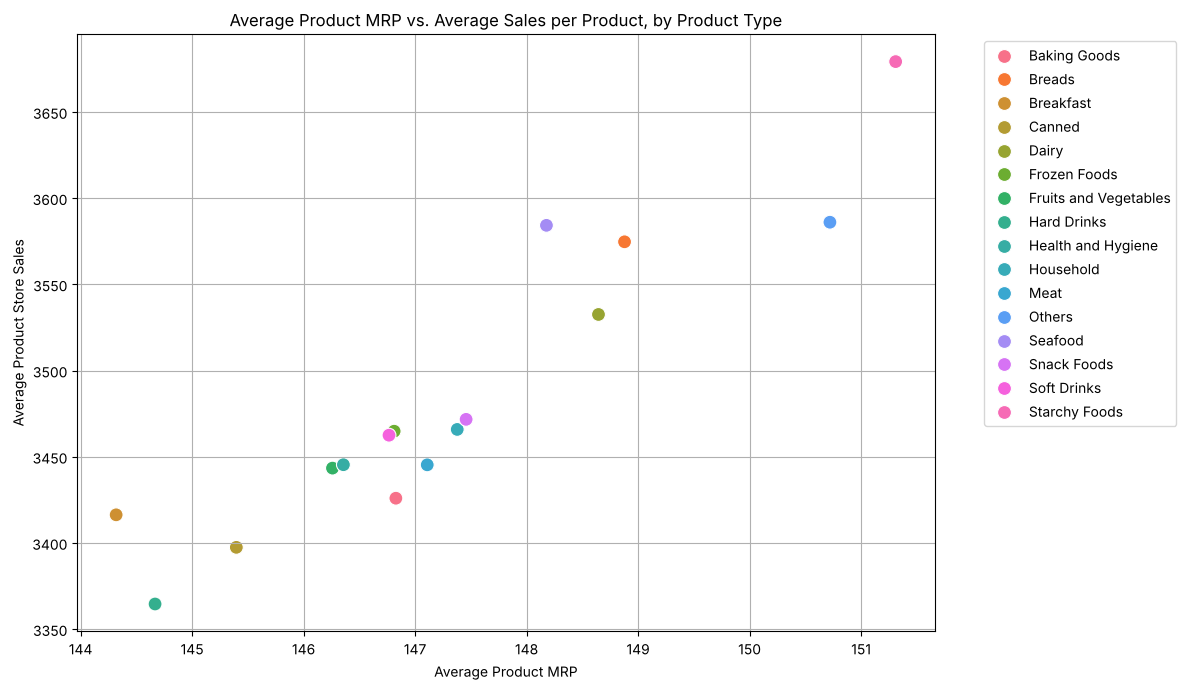

In [86]:
by_type = SuperKart_data.groupby("Product_Type").agg(avg_mrp=("Product_MRP", "mean"),
                                         avg_sales=("Product_Store_Sales_Total", "mean")).reset_index()
plt.figure(figsize=(12, 7))
sns.scatterplot(data=by_type, x="avg_mrp", y="avg_sales", hue="Product_Type", s=100)
plt.title("Average Product MRP vs. Average Sales per Product, by Product Type")
plt.xlabel("Average Product MRP")
plt.ylabel("Average Product Store Sales")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

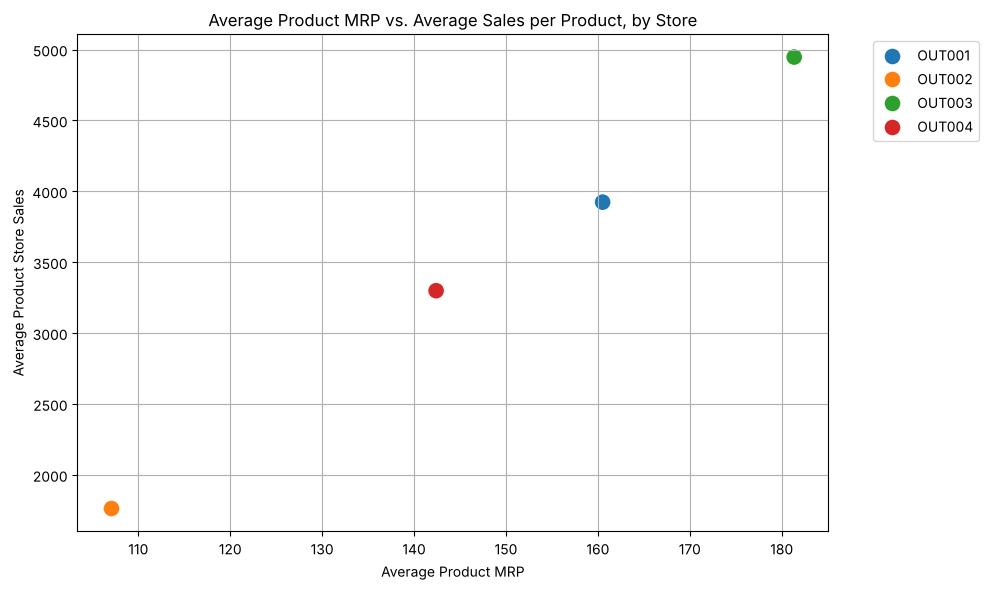

In [87]:
by_store = SuperKart_data.groupby("Store_Id").agg(avg_mrp=("Product_MRP", "mean"),
                                      avg_sales=("Product_Store_Sales_Total", "mean")).reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=by_store, x="avg_mrp", y="avg_sales", hue="Store_Id", s=150)
plt.title("Average Product MRP vs. Average Sales per Product, by Store")
plt.xlabel("Average Product MRP")
plt.ylabel("Average Product Store Sales")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Analysis

- **By product type:** average MRP (about 144-151) and average sales per product (about 3,400-3,700) barely differ between categories, so there is no meaningful price/sales pattern at category level.
- **By store:** the order of average MRP (OUT003 181, OUT001 161, OUT004 142, OUT002 107) is the same as the order of average sales per product (OUT003 4,950, OUT001 3,920, OUT004 3,300, OUT002 1,760). This fits the correlation above, but with four stores it cannot show cause and effect; stores also differ in product weight, format, size and city tier.

### Recommendations for Pricing and Product Strategy

1. **Do not read the store pattern as "raise prices".** Higher-priced stores sell higher-value items to (probably) different customers; test price changes on a few products with a control group before generalising.
2. **Run proper price tests.** The data has no quantity or time dimension, so real elasticity cannot be estimated; collect unit sales and price history.
3. **Use sales per product, not totals,** when comparing categories and stores; totals mostly reflect range size.
4. **Review OUT002 separately.** It has roughly half the sales per product of the other stores.
5. **Use the model for scenario comparison within the four known stores,** not for new locations.